In [1]:
import matplotlib.pyplot as plt
import numpy as np
from taia1dvfd.analysis import LotusData, compute_forecast_score_uv, get_model_variable

In [2]:
OUTPUT_FOLDER = "/home/mnex/Desktop/1DV_FD/experiments/2_Lotus_stationary/output"

def _profile_uv(ax, exp_name: str, n_ens: int = 1000, label = None, color = None):
    z_model, t_model, ue_m, ue_v = get_model_variable(f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    
    # 20 days mean, skip the first 10
    idx_t = np.where(t_model/86400 >= 10)[0]
    uem = np.mean(ue_m[idx_t, :], axis = 0)
    uev = np.mean(ue_v[idx_t, :], axis = 0)

    # u-profile
    ax[0].plot(uem.real, z_model, label = label, color = color)
    ax[0].fill_betweenx(z_model, uem.real - uev.real**0.5, uem.real + uev.real**0.5, alpha = 0.1, color = color)

    # v-profile
    ax[1].plot(uem.imag, z_model, label = label, color = color)
    ax[1].fill_betweenx(z_model, uem.imag - uev.imag**0.5, uem.imag + uev.imag**0.5, alpha = 0.1, color = color)

def _eps(exp_name: str, n_ens: int = 1000):
    obs = LotusData()
    ue_obs = obs.u + 1.j*obs.v
    z_model, t_model, ue_m, ue_v = get_model_variable(f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    return compute_forecast_score_uv(ue_m, ue_v, z_model, t_model, n_ens, ue_obs, obs.z, obs.n)

# Testing the new noise correlated

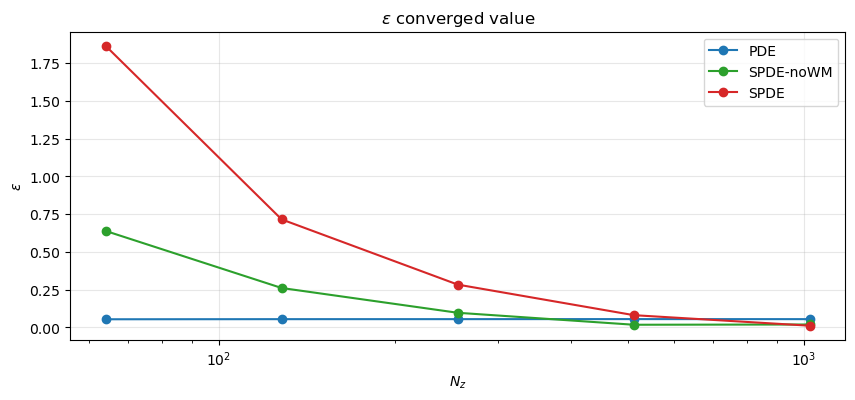

In [3]:
NENS = 1000
NZs = [64, 128, 256, 512, 1024]

def _eps_conv(conf):
    EPS_VALS = []
    for nz in NZs:
        _, vals = _eps(f'nz/{conf}_nz{nz}')
        nt = len(vals)
        eps_converged = np.mean(vals[nt//2:])
        EPS_VALS.append(eps_converged)
    return EPS_VALS

plt.figure(figsize = (10, 4))
plt.title(r'$\varepsilon$ converged value')

plt.plot(NZs, _eps_conv("PDE"), 'o-', label = 'PDE', color = 'C0')
plt.plot(NZs, _eps_conv("SPDE-noWM"), 'o-', label = 'SPDE-noWM', color = 'C2')
plt.plot(NZs, _eps_conv("SPDE"), 'o-', label = 'SPDE', color = 'C3')

plt.xlabel(r'$N_z$')
plt.xscale('log')

plt.ylabel(r'$\varepsilon$')

plt.grid(alpha = 0.3)
plt.legend()

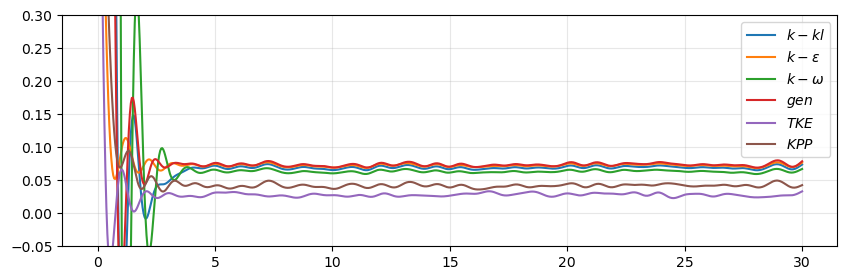

In [4]:
NENS = 1000

plt.figure(figsize = (10, 3))
plt.plot(*_eps(f'k-kl'),      label = r'$k-kl$')
plt.plot(*_eps(f'k-epsilon'), label = r'$k-\varepsilon$')
plt.plot(*_eps(f'k-omega'),   label = r'$k-\omega$')
plt.plot(*_eps(f'gen'),       label = r'$gen$')
plt.plot(*_eps(f'tke'),       label = r'$TKE$')
plt.plot(*_eps(f'kpp'),       label = r'$KPP$')
plt.ylim(-0.05, 0.3)
plt.grid(alpha = 0.3)
plt.legend()

FileNotFoundError: [Errno 2] No such file or directory: '/home/mnex/Desktop/1DV_FD/experiments/2_Lotus_stationary/output/PDE_el1.0_nz64_ne1000.nc'

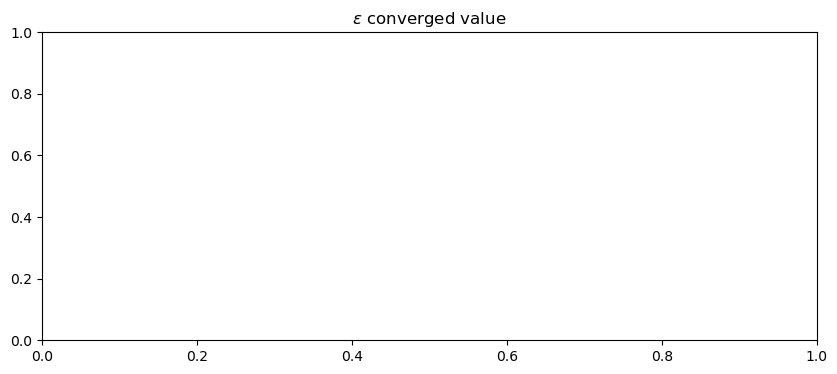

In [5]:
NENS = 1000
NZs = [64, 128, 256, 512, 1024]

def _eps_conv(conf):
    EPS_VALS = []
    for nz in NZs:
        _, vals = _eps(f'{conf}_el1.0_nz{nz}')
        nt = len(vals)
        eps_converged = np.mean(vals[nt//2:])
        EPS_VALS.append(eps_converged)
    return EPS_VALS
    

    
plt.figure(figsize = (10, 4))
plt.title(r'$\varepsilon$ converged value')

plt.plot(NZs, _eps_conv("PDE"), 'o-', label = 'PDE', color = 'C0')
plt.plot(NZs, _eps_conv("SPDE-noWM"), 'o-', label = 'SPDE-noWM', color = 'C2')
plt.plot(NZs, _eps_conv("SPDE"), 'o-', label = 'SPDE', color = 'C3')

plt.xlabel(r'$N_z$')
plt.xscale('log')
plt.grid(alpha = 0.3)
plt.legend()